# Бизнес-кейс №3

Необходимо предсказать, согласится ли клиент открыть срочный вклад по итогам телемаркетинговой кампании, используя демографические признаки, историю контактов и экономические индикаторы

***Задача бинарной классификации***

## Цели и задачи:
1. Оценить качество данных:
    - пропуски данных
    - дубликаты
    - выбросы
2. Очистка/исправление аномалий
3. Ананлиз распределения признаков
4. Исследование взаимосвязи между признаками (корреляция)
5. Сегментировать данные по регионам/экономическо и сравнивать профили с помощью radar chart.
6. Формулировать бизнес-инсайты на основе данных («Что делает песню хитом?»).

## Импорты и настройки

In [129]:
# Основные библиотеки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import pi

# Загрузка данных
from ucimlrepo import fetch_ucirepo 

## Превью DF

In [130]:
# fetch dataset 
bank_marketing = fetch_ucirepo(id=222) 
  
# data (as pandas dataframes) 
X = bank_marketing.data.features 
y = bank_marketing.data.targets 
  
df = pd.concat([X, y], axis=1)
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


### Описание столбцов датасета

In [131]:
pd.set_option('display.max_colwidth', None)
print(list(df.columns))
display(bank_marketing.variables)

['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day_of_week', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


,name,role,type,demographic,description,units,missing_values
0,age,Feature,Integer,Age,None,None,no
1,job,Feature,Categorical,Occupation,"type of job (categorical: 'admin.','blue-collar','entrepreneur','housemaid','management','retired','self-employed','services','student','technician','unemployed','unknown')",None,no
2,marital,Feature,Categorical,Marital Status,"marital status (categorical: 'divorced','married','single','unknown'; note: 'divorced' means divorced or widowed)",None,no
3,education,Feature,Categorical,Education Level,"(categorical: 'basic.4y','basic.6y','basic.9y','high.school','illiterate','professional.course','university.degree','unknown')",None,no
4,default,Feature,Binary,None,has credit in default?,None,no
5,balance,Feature,Integer,None,average yearly balance,euros,no
6,housing,Feature,Binary,None,has housing loan?,None,no
7,loan,Feature,Binary,None,has personal loan?,None,no
8,contact,Feature,Categorical,None,"contact communication type (categorical: 'cellular','telephone')",None,yes
9,day_of_week,Feature,Date,None,last contact day of the week,None,no


### Выводы
Признаки в наборе делятся на три логические категории:
- **Данные о клиенте.** Возраст (age), род занятий (job), семейное положение (marital), образование (education), наличие дефолта (default), среднегодовой баланс в евро (balance), наличие ипотеки (housing) и потребительского кредита (loan).

- **Детали последнего контакта.** Тип связи (contact — мобильный или городской), день месяца (day), месяц (month) и длительность звонка в секундах (duration).

- **История маркетинговых кампаний.** Количество контактов с клиентом в текущей кампании (campaign), число дней с прошлого звонка (pdays), количество прошлых контактов (previous) и результат предыдущей кампании (poutcome).

## Первичный осмотр данных 

### Первый взгляд на данные

In [132]:
df.head(10)

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no
5,35,management,married,tertiary,no,231,yes,no,NaN,5,may,139,1,-1,0,NaN,no
6,28,management,single,tertiary,no,447,yes,yes,NaN,5,may,217,1,-1,0,NaN,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,NaN,5,may,380,1,-1,0,NaN,no
8,58,retired,married,primary,no,121,yes,no,NaN,5,may,50,1,-1,0,NaN,no
9,43,technician,single,secondary,no,593,yes,no,NaN,5,may,55,1,-1,0,NaN,no


In [133]:
df.sample(30, random_state=50)

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
33955,32,services,married,secondary,no,386,no,no,cellular,30,apr,222,1,-1,0,NaN,no
34904,26,management,single,tertiary,no,1494,yes,no,cellular,6,may,477,2,-1,0,NaN,no
5547,38,blue-collar,married,secondary,no,1102,yes,no,NaN,23,may,159,3,-1,0,NaN,no
15633,41,technician,married,secondary,no,525,yes,no,cellular,21,jul,108,1,-1,0,NaN,no
41402,19,student,single,secondary,no,4,no,no,cellular,3,sep,114,1,-1,0,NaN,no
20608,43,management,single,tertiary,no,1627,no,no,cellular,12,aug,105,4,-1,0,NaN,no
38208,24,admin.,married,secondary,no,-94,yes,no,cellular,15,may,217,1,-1,0,NaN,no
30621,36,unemployed,married,primary,no,0,no,no,cellular,6,feb,409,1,-1,0,NaN,no
8247,44,blue-collar,divorced,primary,yes,-119,yes,no,NaN,2,jun,132,5,-1,0,NaN,no
10630,50,blue-collar,married,secondary,no,887,no,no,NaN,16,jun,287,1,-1,0,NaN,no


#### Что бросатеся в глаза в результате беглого осмотра срезов и требует исследования:
1. pdays = -1
2. poutcome = NaN
3. previous = 0


### Технический паспорт данных

In [134]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          45211 non-null  int64 
 1   job          44923 non-null  object
 2   marital      45211 non-null  object
 3   education    43354 non-null  object
 4   default      45211 non-null  object
 5   balance      45211 non-null  int64 
 6   housing      45211 non-null  object
 7   loan         45211 non-null  object
 8   contact      32191 non-null  object
 9   day_of_week  45211 non-null  int64 
 10  month        45211 non-null  object
 11  duration     45211 non-null  int64 
 12  campaign     45211 non-null  int64 
 13  pdays        45211 non-null  int64 
 14  previous     45211 non-null  int64 
 15  poutcome     8252 non-null   object
 16  y            45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


### Анализ `.info()`:

| Метрика | Значение | Вывод |
|---------|----------|-------|
| **Типы данных** | int64(7), object(10) | OK, но можно оптимизировать |
| **Пропуски** | Есть в `job`, `education`, `contact`, `poutcome` | Нужно исследовать |


#### Оптимизация памяти

In [135]:
# Анализ типов данных
df.dtypes.value_counts()

object    10
int64      7
Name: count, dtype: int64

In [136]:
# Замер памяти до оптимизации
memory_before = df.memory_usage(deep=True).sum() / 1024**2

# Числовые типы
# выбрать атоматически
int_cols = df.select_dtypes(include=['int64']).columns

for col in int_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], downcast='integer')

# Категориальные типы (уникальность < 20%)
cat_candidates = df.select_dtypes(include=['object']).columns
for col in cat_candidates:
    if col in df.columns:
        unique_ratio = df[col].nunique() / len(df)
        if unique_ratio < 0.2:
            df[col] = df[col].astype('category')
            print(f" {col} → category (уникальность: {unique_ratio:.1%})")

# Замер памяти после оптимизации
memory_after = df.memory_usage(deep=True).sum() / 1024**2

# Вывод
print(f"\n💾 Память до: {memory_before:.2f} MB")
print(f"\n💾 Память после: {memory_after:.2f} MB")
print(f"\n📉 Экономия: {(1 - memory_after/memory_before)*100:.1f}%")

 job → category (уникальность: 0.0%)
 marital → category (уникальность: 0.0%)
 education → category (уникальность: 0.0%)
 default → category (уникальность: 0.0%)
 housing → category (уникальность: 0.0%)
 loan → category (уникальность: 0.0%)
 contact → category (уникальность: 0.0%)
 month → category (уникальность: 0.0%)
 poutcome → category (уникальность: 0.0%)
 y → category (уникальность: 0.0%)

💾 Память до: 27.61 MB

💾 Память после: 1.00 MB

📉 Экономия: 96.4%


In [137]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   age          45211 non-null  int8    
 1   job          44923 non-null  category
 2   marital      45211 non-null  category
 3   education    43354 non-null  category
 4   default      45211 non-null  category
 5   balance      45211 non-null  int32   
 6   housing      45211 non-null  category
 7   loan         45211 non-null  category
 8   contact      32191 non-null  category
 9   day_of_week  45211 non-null  int8    
 10  month        45211 non-null  category
 11  duration     45211 non-null  int16   
 12  campaign     45211 non-null  int8    
 13  pdays        45211 non-null  int16   
 14  previous     45211 non-null  int16   
 15  poutcome     8252 non-null   category
 16  y            45211 non-null  category
dtypes: category(10), int16(3), int32(1), int8(3)
memory usage: 1017.4 KB


**Выявлена ошибка именования** 
day_of_week - явно обозначает день месяца


In [138]:
df = df.rename(columns={'day_of_week': 'day_of_month'})

### Статистическая сводка

In [139]:
# Числовые переменные
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day_of_month,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


In [140]:
# Категориальные переменные
df.describe(include=['category']).T

,count,unique,top,freq
job,44923,11,blue-collar,9732
marital,45211,3,married,27214
education,43354,3,secondary,23202
default,45211,2,no,44396
housing,45211,2,yes,25130
loan,45211,2,no,37967
contact,32191,2,cellular,29285
month,45211,12,may,13766
poutcome,8252,3,failure,4901
y,45211,2,no,39922


## Качество данных

### Анализ пропусков

In [141]:
# Количество пропусков
missing_count = df.isna().sum()
missing_pct = (df.isna().mean() * 100).round(2)

missing_df = pd.DataFrame({
    'Пропуски': missing_count,
    '%': missing_pct
}).query('Пропуски > 0').sort_values('Пропуски', ascending=False)

print("📊 Пропуски в данных:")
missing_df

📊 Пропуски в данных:


,Пропуски,%
poutcome,36959,81.75
contact,13020,28.80
education,1857,4.11
job,288,0.64



--- Признак: poutcome ---
          Количество  Конверсия (%)
poutcome                           
success         1511          64.73
other           1840          16.68
failure         4901          12.61
unknown        36959           9.16

--- Признак: contact ---
           Количество  Конверсия (%)
contact                             
cellular        29285          14.92
telephone        2906          13.42
unknown         13020           4.07

--- Признак: education ---
           Количество  Конверсия (%)
education                           
tertiary        13301          15.01
unknown          1857          13.57
secondary       23202          10.56
primary          6851           8.63

--- Признак: job ---
               Количество  Конверсия (%)
job                                     
student               938          28.68
retired              2264          22.79
unemployed           1303          15.50
management           9458          13.76
admin.               5171   

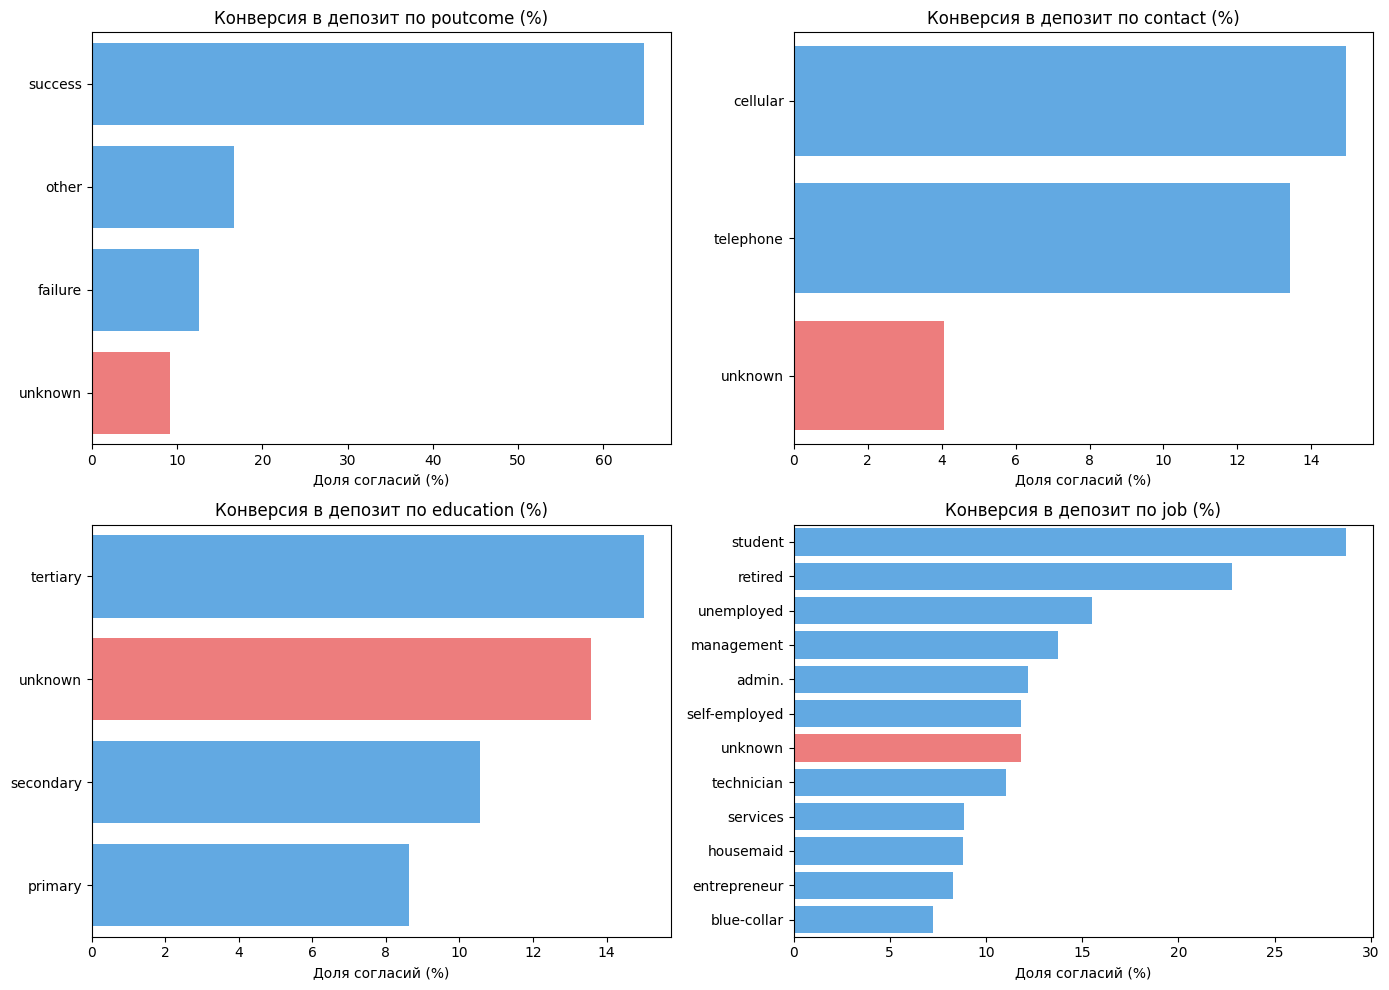

In [142]:
cols_with_na = ['poutcome', 'contact', 'education', 'job']

target_num = df['y'].astype(str).isin(['yes', '1']).astype(int)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(cols_with_na):
    temp_series = df[col].astype(str).replace('nan', 'unknown').fillna('unknown')
    
    stats = pd.DataFrame({
        'Количество': temp_series.value_counts(),
        'Конверсия (%)': (target_num.groupby(temp_series).mean() * 100).round(2)
    }).sort_values(by='Конверсия (%)', ascending=False)
    
    print(f"\n--- Признак: {col} ---")
    print(stats)

    colors = ['#ff6b6b' if idx == 'unknown' else '#4dabf7' for idx in stats.index]
    sns.barplot(x=stats['Конверсия (%)'], y=stats.index, ax=axes[i], palette=colors, hue=stats.index, legend=False)
    axes[i].set_title(f'Конверсия в депозит по {col} (%)')
    axes[i].set_xlabel('Доля согласий (%)')
    axes[i].set_ylabel('')

plt.tight_layout()
plt.show()

#### Вывод
1. Строк с пропусками в job всего 288 (это менее 0.64 % от всех 45 211 записей), а их конверсия (11.81 %) почти не отличается от средней по всей выборке (11.70 %) - удаляем

In [143]:
df = df.dropna(subset=['job']).reset_index(drop=True)

### Анализ выбросов

 Признак   Min  50% (Медиана)    95%     99%    Max  Верхняя граница IQR  Выбросов по IQR (%)
 balance -8019          447.0 5763.0 13159.1 102127               3444.5                10.49
     age    18           39.0   59.0    71.0     95                 70.5                 1.07
campaign     1            2.0    8.0    16.0     63                  6.0                 6.75
   pdays    -1           -1.0  318.0   370.0    871                 -1.0                18.31
previous     0            0.0    3.0     9.0    275                  0.0                18.31


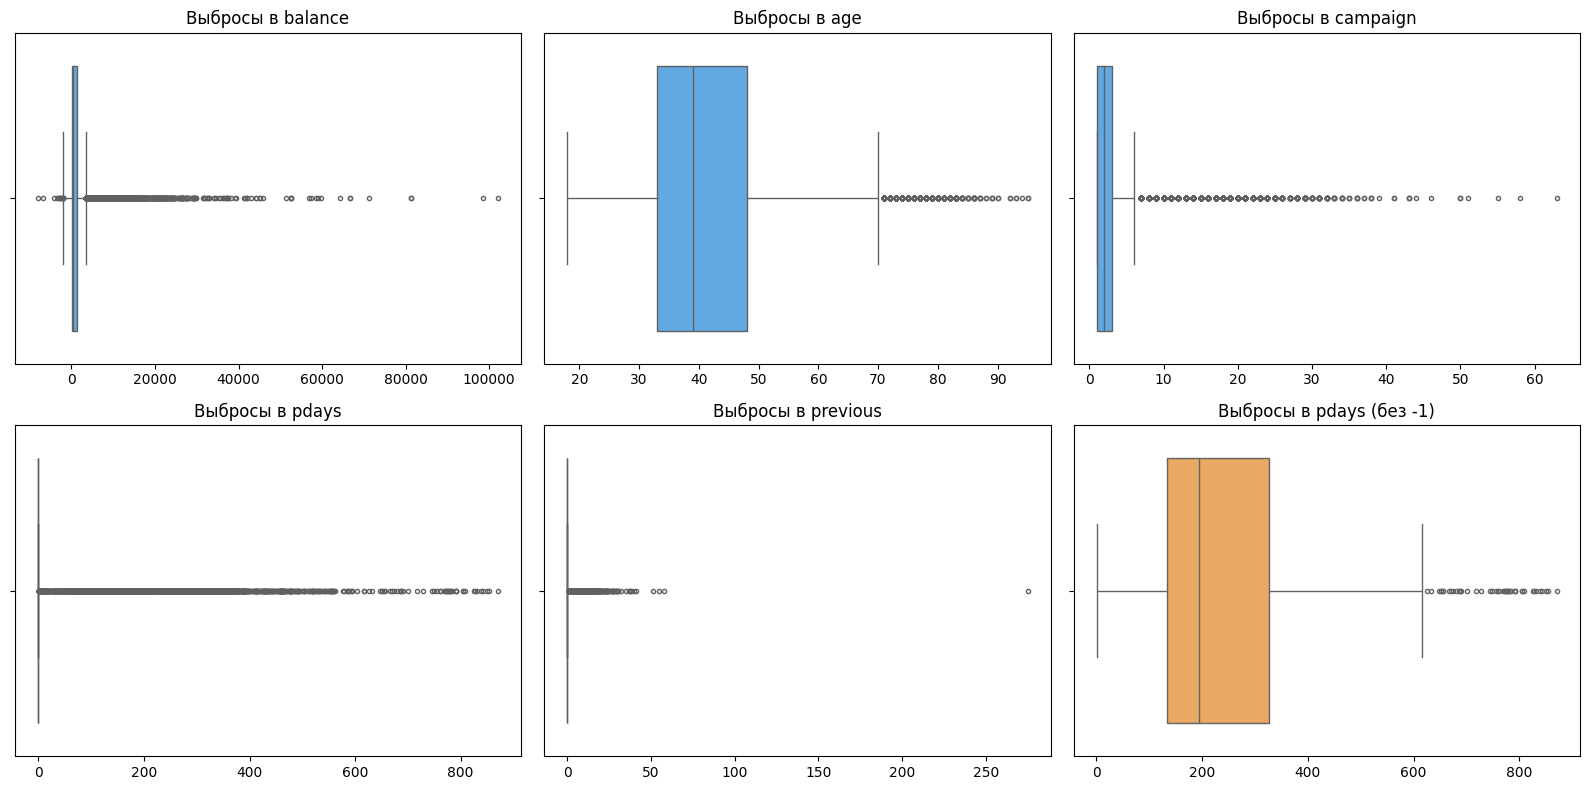

In [144]:
num_cols = ['balance', 'age', 'campaign', 'pdays', 'previous']

# 1. Сводная таблица квантилей и границ IQR
outlier_summary = []

for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    outliers_cnt = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    
    outlier_summary.append({
        'Признак': col,
        'Min': df[col].min(),
        '50% (Медиана)': df[col].median(),
        '95%': round(df[col].quantile(0.95), 1),
        '99%': round(df[col].quantile(0.99), 1),
        'Max': df[col].max(),
        'Верхняя граница IQR': round(upper_bound, 1),
        'Выбросов по IQR (%)': round(outliers_cnt / len(df) * 100, 2)
    })

summary_df = pd.DataFrame(outlier_summary)
print(summary_df.to_string(index=False))

# 2. Визуализация распределений и выбросов (Boxplot)
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(x=df[col], ax=axes[i], color='#4dabf7', fliersize=3)
    axes[i].set_title(f'Выбросы в {col}')
    axes[i].set_xlabel('')

# Отдельно посмотрим pdays без значения -1
sns.boxplot(x=df.loc[df['pdays'] != -1, 'pdays'], ax=axes[5], color='#ffa94d', fliersize=3)
axes[5].set_title('Выбросы в pdays (без -1)')
axes[5].set_xlabel('')

plt.tight_layout()
plt.show()


#### Выводы
| Признак | Выбросы | Интерпретация |
|---------|---------|---------------|
| **balance** | Много > 10k | богатые клиенты (есть средства открыть вклад) |
| **age** | Немного | Пенсионеры (пенсионеры обычно любят вклады) |
| **campaign** | 1% > 16 | избавиться от хвоста |
| **pdays** | много -1 | проверим связь с  previous скорее всего тех признак|
| **previous** | много 0 | проверим связь pdays |

### Проверка аномалий

In [145]:
display(df[(df['pdays'] == -1) & (df['previous'] == 0)].head(15))
print(f"\nСтрок с pdays = -1: {len(df[df['pdays'] == -1])}")
print(f"\nСтрок с previous = 0 дней: {len(df[df['previous'] == 0])}")
print(f"\nСтрок обладающих одновременно признаками: {len(df[(df['pdays'] == -1) & (df['previous'] == 0)])}")

,age,job,marital,education,default,balance,housing,loan,contact,day_of_month,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,35,management,married,tertiary,no,231,yes,no,NaN,5,may,139,1,-1,0,NaN,no
5,28,management,single,tertiary,no,447,yes,yes,NaN,5,may,217,1,-1,0,NaN,no
6,42,entrepreneur,divorced,tertiary,yes,2,yes,no,NaN,5,may,380,1,-1,0,NaN,no
7,58,retired,married,primary,no,121,yes,no,NaN,5,may,50,1,-1,0,NaN,no
8,43,technician,single,secondary,no,593,yes,no,NaN,5,may,55,1,-1,0,NaN,no
9,41,admin.,divorced,secondary,no,270,yes,no,NaN,5,may,222,1,-1,0,NaN,no



Строк с pdays = -1: 36699

Строк с previous = 0 дней: 36699

Строк обладающих одновременно признаками: 36699


### Вывод
Это новые клиенты, по которым нет данных о прошлых компаниях.

In [146]:
df[(df['pdays'] != -1) & (df['previous'] != 0) & (df['poutcome'].isna()) ]


,age,job,marital,education,default,balance,housing,loan,contact,day_of_month,month,duration,campaign,pdays,previous,poutcome,y
40415,61,retired,married,tertiary,no,3140,yes,yes,cellular,6,aug,975,4,98,1,NaN,yes
41568,39,management,married,tertiary,no,184,no,no,cellular,15,oct,206,1,168,5,NaN,no
41783,26,admin.,single,secondary,no,338,no,no,cellular,29,oct,209,1,188,2,NaN,yes
43704,30,technician,single,secondary,no,254,yes,yes,cellular,24,jun,167,3,416,2,NaN,no
44735,37,management,married,secondary,no,209,no,no,cellular,14,oct,183,3,528,7,NaN,no


In [147]:
df[df['poutcome'] == 'other'].sample(30, random_state=50)

,age,job,marital,education,default,balance,housing,loan,contact,day_of_month,month,duration,campaign,pdays,previous,poutcome,y
33429,29,blue-collar,married,secondary,no,457,yes,no,cellular,20,apr,72,3,341,1,other,no
27307,44,blue-collar,married,primary,no,0,yes,yes,cellular,21,nov,32,2,116,3,other,no
44670,51,management,married,tertiary,no,5108,yes,no,cellular,8,oct,272,1,102,8,other,no
44294,29,management,single,tertiary,no,1673,no,no,cellular,16,aug,200,2,159,3,other,no
41417,41,admin.,married,secondary,no,158,yes,no,cellular,1,oct,250,2,120,4,other,no
43295,37,admin.,married,secondary,no,55,yes,yes,cellular,27,apr,99,1,329,4,other,no
33346,37,technician,single,secondary,no,442,yes,no,cellular,20,apr,51,4,349,1,other,no
44066,47,management,divorced,tertiary,no,-130,yes,no,cellular,30,jul,221,4,431,5,other,no
41187,26,management,single,tertiary,no,9447,no,no,cellular,4,sep,113,1,100,2,other,no
33222,34,technician,divorced,secondary,no,0,yes,yes,cellular,20,apr,110,3,269,2,other,no


### Вывод
Выявлены некорреткно внесенные данные у 5 повторных клиентов
 - можно удалить
 - или присвоить значение other (так как выглядит это как человеческий фактор лучше этот вариант)

In [148]:
mask_returning_na = (df['pdays'] != -1) & (df['poutcome'].isna())
df.loc[mask_returning_na, 'poutcome'] = 'other'

In [149]:
df[df['job'].isna()]

,age,job,marital,education,default,balance,housing,loan,contact,day_of_month,month,duration,campaign,pdays,previous,poutcome,y


### Выводы
1. Далее можно анализировать 3 выборки: общая, новые клиенты и старые
2. В общей выборке признаки pdays, previous и poutcome будут иметь низкую конверсию, добавим бинарный признак новый или старый клиент
3. Для новых клиентов pdays, previous и poutcome не имеют смысла удалим признаки


In [150]:
df[df['pdays'] == -1]

,age,job,marital,education,default,balance,housing,loan,contact,day_of_month,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,35,management,married,tertiary,no,231,yes,no,NaN,5,may,139,1,-1,0,NaN,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44915,23,student,single,tertiary,no,113,no,no,cellular,17,nov,266,1,-1,0,NaN,yes
44917,25,technician,single,secondary,no,505,no,yes,cellular,17,nov,386,2,-1,0,NaN,yes
44918,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,NaN,yes
44919,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,NaN,yes
